# 01 · Explore LOLA south pole data

**Milestone 1 of the Lunar Hazard Map.** This notebook loads NASA's LOLA laser-altimeter maps of the lunar south pole and checks them before anything gets trained. It answers five questions:

1. **What do the files look like?** Grid size, pixel size, projection, no-data values.
2. **Can we trust the slope layer?** We recompute slope from elevation and compare it to NASA's slope map.
3. **What does a first hazard map look like?** Safe / caution / no-go from slope alone, at 80 m.
4. **Where are the permanently shadowed regions (PSRs)?** Including the one on Shackleton's floor (Lantern Profile 1).
5. **How much of the 5 m map is real data, and how much does a coarse map miss?** These two numbers decide whether the U-Net idea is worth it.

**Before running:** run `download_m1.sh` first (about 0.8 GB into `~/lunar/data`). Section F also reads a 12 × 12 km window of two large 5 m files straight from NASA's server over HTTP, so you need internet for that section the first time. After that it uses a local cached copy.

**Number labels used below.** *Sourced* = from a cited page or paper. *Placeholder* = a setting we picked that still has to be confirmed. *Measured* = computed in this notebook from the data.

**Data citations:** Barker et al. 2023, *Planet. Sci. J.* 4, 183, doi:10.3847/PSJ/acf3e1 (80 m layers, roughness, PSR map). Barker et al. 2021, *Planet. Space Sci.* 203, 105119, doi:10.1016/j.pss.2020.105119 (5 m mosaic).

## Setup

In [16]:
import os, json, time, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Circle, Patch, Rectangle
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window, from_bounds
from affine import Affine
import geopandas as gpd
from shapely.geometry import Point

plt.rcParams.update({"figure.dpi": 110, "image.origin": "upper"})
pd.set_option("display.width", 160)

In [17]:
# ---------------- Settings ----------------
DATA = Path(os.environ.get("LUNAR_DATA", Path.home() / "lunar" / "data"))
CROPS = DATA / "crops"                  # small cached 5 m windows (reused by 02_make_labels)
FIG = Path("figures"); RESULTS = Path("results")
for d in (CROPS, FIG, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

# Where the big 5 m files live if they are not in DATA (read window-by-window over HTTP)
FIVE_M_SOURCE = os.environ.get("LUNAR_5M_SOURCE", "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/87S")

# Hazard thresholds (degrees). Change these to match whatever rover the team picks.
SAFE_MAX_DEG = 15.0   # SOURCED: NASA VIPER page, "capable of traversing an incline of as much as 15 degrees"
NOGO_MIN_DEG = 25.0   # PLACEHOLDER: from the project plan, not tied to a specific rover yet

MOON_R = 1_737_400.0  # m, LOLA reference sphere radius used by the polar stereographic grid
SHACKLETON_LAT, SHACKLETON_LON = -89.67, 129.78   # SOURCED: USGS Gazetteer of Planetary Nomenclature (IAU)
SHACKLETON_DIAM_KM = 20.92                         # SOURCED: same USGS entry
CROP_KM = 12.0        # side of the 5 m study window (setting). Centered between the pole and Shackleton's
                      # center, so it covers the sunlit rim, the ~30 deg inner wall and part of the shadowed floor.
RUN_FULL_COUNT = True # Section G: scan the whole 5 m count map (about a minute)

F80 = {
    "elev":  DATA / "LDEM_80S_80MPP_ADJ.TIF",       # height, m
    "slope": DATA / "LDSM_80S_80MPP_ADJ.TIF",       # slope, deg
    "count": DATA / "LDEC_80S_80MPP_ADJ.TIF",       # LOLA shots per pixel
    "hill":  DATA / "LDEM_80S_80MPP_ADJ_HILL.TIF",  # hillshade
    "rough": DATA / "LDRM_80S_1000MPP_ADJ_ROUGH_100M.TIF",  # roughness, m (1 km pixels, 100 m baseline)
}
PSR_SHP = DATA / "LPSR_80S_20MPP_ADJ_1km2.SHP"     # PSRs larger than 1 km^2
F5 = {"elev": "ldem_87s_5mpp.tif", "slope": "ldsm_87s_5mpp.tif", "count": "ldec_87s_5mpp.tif"}

missing = [p.name for p in [*F80.values(), PSR_SHP] if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing in {DATA}: {missing}\nRun download_m1.sh first (separate terminal tab).")
print("Data folder:", DATA)
print("All 80 m files and the PSR shapefile found.")

Data folder: /Users/razbinkarkidoli/lunar/data
All 80 m files and the PSR shapefile found.


In [18]:
# ---------------- Helpers ----------------
GDAL_HTTP_ENV = dict(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",       # don't list the remote folder
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.TIF",
    GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES",
    GDAL_HTTP_MAX_RETRY="5", GDAL_HTTP_RETRY_DELAY="2",
    VSI_CACHE="TRUE",
)

def read(path, window=None, out_shape=None, resampling=Resampling.nearest):
    # Read band 1 as float32 with every kind of no-data turned into NaN. Returns (array, transform).
    with rasterio.Env(**GDAL_HTTP_ENV), rasterio.open(path) as s:
        a = s.read(1, window=window, out_shape=out_shape, masked=True, resampling=resampling)
        t = s.window_transform(window) if window is not None else s.transform
        if out_shape is not None and window is None:
            t = t * Affine.scale(s.width / out_shape[1], s.height / out_shape[0])
    a = np.ma.filled(a.astype("float32"), np.nan)
    a[~np.isfinite(a) | (np.abs(a) > 1e30)] = np.nan
    return a, t

def extent_km(t, shape):
    h, w = shape
    return [t.c / 1e3, (t.c + t.a * w) / 1e3, (t.f + t.e * h) / 1e3, t.f / 1e3]

def latlon_to_xy(lat, lon):
    # South polar stereographic (sphere): x = rho*sin(lon), y = rho*cos(lon)
    rho = 2 * MOON_R * np.tan(np.radians(90 + np.asarray(lat)) / 2)
    return rho * np.sin(np.radians(lon)), rho * np.cos(np.radians(lon))

def xy_to_latlon(x, y):
    rho = np.hypot(x, y)
    lat = -(90 - np.degrees(2 * np.arctan(rho / (2 * MOON_R))))
    lon = np.degrees(np.arctan2(x, y)) % 360
    return lat, lon

def slope_deg(dem, res):
    gy, gx = np.gradient(dem, res)
    return np.degrees(np.arctan(np.hypot(gx, gy))).astype("float32")

def hillshade(dem, res, azimuth=45, altitude=45):
    gy, gx = np.gradient(dem, res)
    slope = np.arctan(np.hypot(gx, gy))
    aspect = np.arctan2(-gy, -gx)
    az, zen = np.radians(360 - azimuth + 90), np.radians(90 - altitude)
    hs = np.cos(zen) * np.cos(slope) + np.sin(zen) * np.sin(slope) * np.cos(az - aspect)
    return np.clip(hs, 0, 1).astype("float32")

NODATA_CLASS = 255
CLASS_NAMES = ["safe", "caution", "no-go"]
CLASS_CMAP = ListedColormap(["#2e9e5b", "#f0b429", "#d64545"])

def classify(slope):
    # 0 = safe (< SAFE_MAX), 1 = caution, 2 = no-go (>= NOGO_MIN), 255 = no data
    c = np.full(slope.shape, NODATA_CLASS, np.uint8)
    ok = np.isfinite(slope)
    c[ok & (slope < SAFE_MAX_DEG)] = 0
    c[ok & (slope >= SAFE_MAX_DEG) & (slope < NOGO_MIN_DEG)] = 1
    c[ok & (slope >= NOGO_MIN_DEG)] = 2
    return c

def class_fractions(c):
    v = c[c != NODATA_CLASS]
    return {n: float((v == i).mean()) for i, n in enumerate(CLASS_NAMES)}

def show_classes(ax, c, extent, title):
    ax.imshow(np.ma.masked_equal(c, NODATA_CLASS), cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5,
              extent=extent, interpolation="nearest")
    ax.set_title(title)
    ax.legend(handles=[Patch(color=CLASS_CMAP(i), label=f"{n}") for i, n in enumerate(CLASS_NAMES)],
              loc="lower right", fontsize=7)

def subset(a, t, xmin, xmax, ymin, ymax):
    # Cut a box (meters) out of an in-memory grid. Returns (sub-array, extent_km).
    c0, c1 = int((xmin - t.c) // t.a), int(math.ceil((xmax - t.c) / t.a))
    r0, r1 = int((ymax - t.f) // t.e), int(math.ceil((ymin - t.f) / t.e))
    c0, r0 = max(c0, 0), max(r0, 0)
    sub = a[r0:r1, c0:c1]
    return sub, extent_km(t * Affine.translation(c0, r0), sub.shape)

def source_5m(name):
    # Prefer a local full download, otherwise read from FIVE_M_SOURCE (HTTP -> /vsicurl/).
    local = DATA / name
    if local.exists():
        return str(local), False
    src = f"{FIVE_M_SOURCE.rstrip('/')}/{name}"
    return (f"/vsicurl/{src}", True) if src.startswith("http") else (src, False)

def km_label(ax):
    ax.set_xlabel("x (km, polar stereographic)"); ax.set_ylabel("y (km)")

SHACK_XY = latlon_to_xy(SHACKLETON_LAT, SHACKLETON_LON)
_cx, _cy = SHACK_XY[0] / 2, SHACK_XY[1] / 2       # midpoint between the pole (0,0) and Shackleton's center
_h = CROP_KM * 1000 / 2
CROP_BOUNDS = (_cx - _h, _cy - _h, _cx + _h, _cy + _h)   # left, bottom, right, top (m)
print(f"Shackleton center: x={SHACK_XY[0]/1e3:.2f} km, y={SHACK_XY[1]/1e3:.2f} km "
      f"({np.hypot(*SHACK_XY)/1e3:.1f} km from the pole)")
print("5 m study window (km, left/bottom/right/top):", [round(float(b) / 1e3, 2) for b in CROP_BOUNDS])

Shackleton center: x=7.69 km, y=-6.40 km (10.0 km from the pole)
5 m study window (km, left/bottom/right/top): [-2.15, -9.2, 9.85, 2.8]


## A · What the 80 m files look like

The 80 m files cover 80–90°S on one grid. Every layer should have the same size, pixel and projection. If a row below disagrees, stop and check the download.

In [19]:
rows = []
for key, p in F80.items():
    with rasterio.open(p) as s:
        rows.append(dict(layer=key, file=p.name, width=s.width, height=s.height, pixel_m=round(s.res[0], 2),
                         dtype=s.dtypes[0], nodata=s.nodata, tiled=s.profile.get("tiled"),
                         overviews=s.overviews(1)))
display(pd.DataFrame(rows))
with rasterio.open(F80["elev"]) as s:
    CRS80 = s.crs
    print("CRS:", s.crs.to_wkt()[:400] if s.crs else None, "...")
    print("Bounds (km):", [round(b / 1e3, 1) for b in s.bounds])

# Cross-check our lat/lon -> x/y formula against the file's own projection (if pyproj can read it)
try:
    from pyproj import CRS, Transformer
    c = CRS.from_wkt(CRS80.to_wkt())
    tr = Transformer.from_crs(c.geodetic_crs, c, always_xy=True)
    px, py = tr.transform(SHACKLETON_LON, SHACKLETON_LAT)
    print(f"Projection check at Shackleton: formula vs pyproj differ by {np.hypot(px-SHACK_XY[0], py-SHACK_XY[1]):.1f} m")
except Exception as e:
    print("pyproj cross-check skipped:", e)

,layer,file,width,height,pixel_m,dtype,nodata,tiled,overviews
0,elev,LDEM_80S_80MPP_ADJ.TIF,7600,7600,80.0,float32,NaN,True,"[2, 4, 8, 16]"
1,slope,LDSM_80S_80MPP_ADJ.TIF,7600,7600,80.0,float32,NaN,True,"[2, 4, 8, 16]"
2,count,LDEC_80S_80MPP_ADJ.TIF,7600,7600,80.0,float32,NaN,True,"[2, 4, 8, 16]"
3,hill,LDEM_80S_80MPP_ADJ_HILL.TIF,7600,7600,80.0,float32,0.0,True,"[2, 4, 8, 16]"
4,rough,LDRM_80S_1000MPP_ADJ_ROUGH_100M.TIF,608,608,1000.0,float32,NaN,True,[2]


CRS: PROJCS["Moon (2015) - Sphere / Ocentric / South Polar",GEOGCS["Moon (2015) - Sphere / Ocentric",DATUM["Moon (2015) - Sphere",SPHEROID["Moon (2015) - Sphere",1737400,0,AUTHORITY["IAU","30100"]],AUTHORITY["IAU","30100"]],PRIMEM["Reference Meridian",0,AUTHORITY["IAU","30100"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["IAU","30100"]],PROJECTION["Polar_Stereographic"],PARAME ...
Bounds (km): [-304.0, -304.0, 304.0, 304.0]
Projection check at Shackleton: formula vs pyproj differ by 0.0 m


Grid (7600, 7600), pixel 80 m, 100.0% of pixels have data
Elevation range: -7,296 to 7,026 m
Slope: median 7.9 deg, 99th pct 27.0 deg


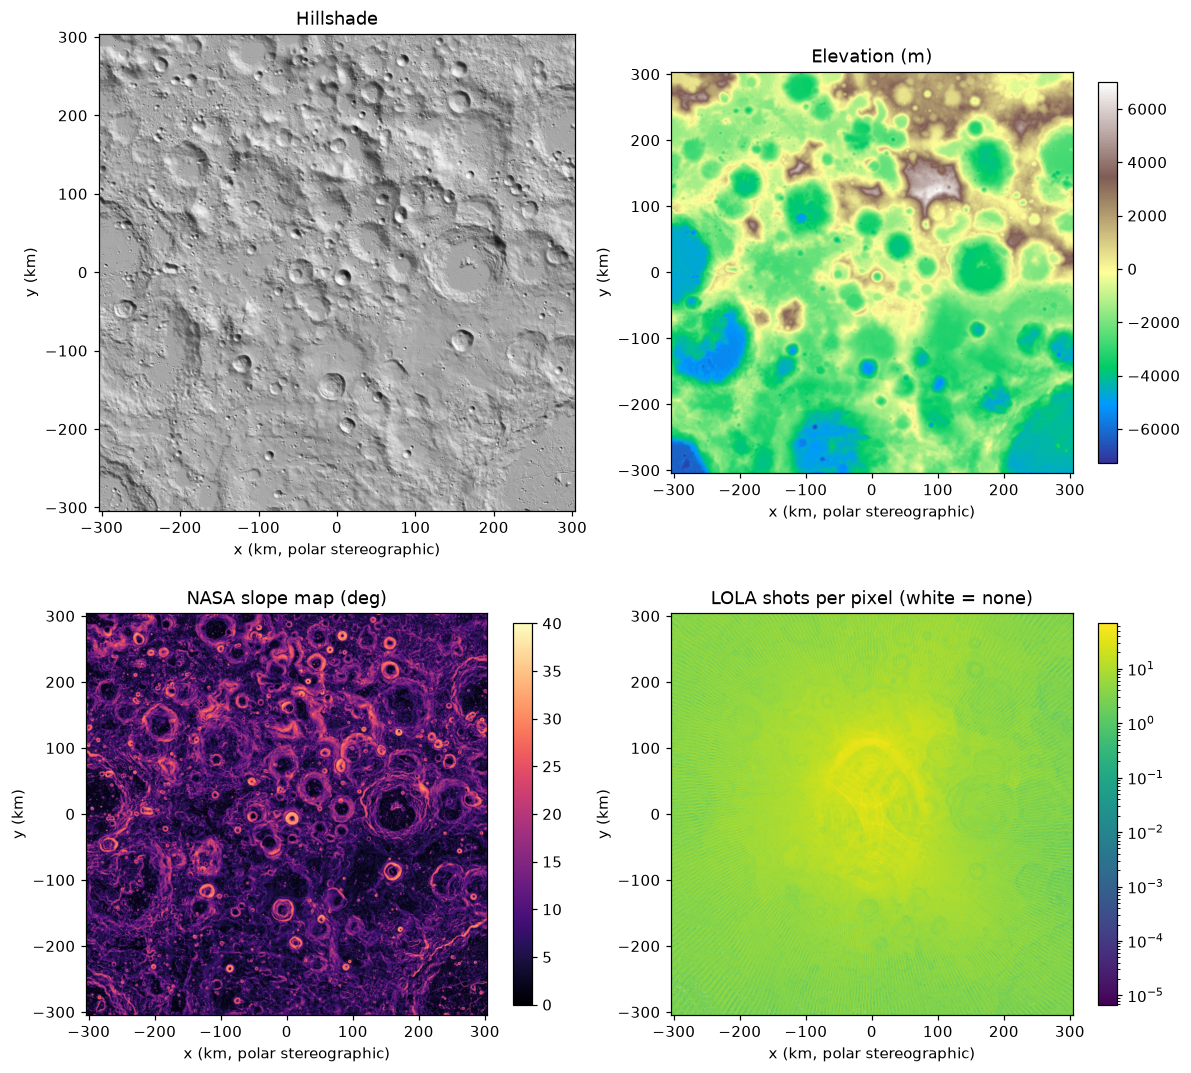

In [20]:
elev80, t80 = read(F80["elev"])
slope80, ts80 = read(F80["slope"])
assert elev80.shape == slope80.shape and t80 == ts80, "elevation and slope grids don't match"
RES80 = t80.a
ext80 = extent_km(t80, elev80.shape)
small = (elev80.shape[0] // 4, elev80.shape[1] // 4)          # quarter-size reads for display only
hill80s, _ = read(F80["hill"], out_shape=small, resampling=Resampling.average)
count80s, _ = read(F80["count"], out_shape=small, resampling=Resampling.nearest)

print(f"Grid {elev80.shape}, pixel {RES80:.0f} m, {np.isfinite(elev80).mean():.1%} of pixels have data")
print(f"Elevation range: {np.nanmin(elev80):,.0f} to {np.nanmax(elev80):,.0f} m")
print(f"Slope: median {np.nanmedian(slope80):.1f} deg, 99th pct {np.nanpercentile(slope80, 99):.1f} deg")

fig, ax = plt.subplots(2, 2, figsize=(11, 10))
ax[0, 0].imshow(hill80s, cmap="gray", extent=ext80); ax[0, 0].set_title("Hillshade")
im = ax[0, 1].imshow(elev80[::4, ::4], cmap="terrain", extent=ext80); ax[0, 1].set_title("Elevation (m)")
plt.colorbar(im, ax=ax[0, 1], shrink=0.8)
im = ax[1, 0].imshow(slope80[::4, ::4], cmap="magma", vmin=0, vmax=40, extent=ext80); ax[1, 0].set_title("NASA slope map (deg)")
plt.colorbar(im, ax=ax[1, 0], shrink=0.8)
cm = plt.get_cmap("viridis").copy(); cm.set_bad("white")
im = ax[1, 1].imshow(np.ma.masked_less_equal(count80s, 0), cmap=cm, norm=LogNorm(), extent=ext80)
ax[1, 1].set_title("LOLA shots per pixel (white = none)")
plt.colorbar(im, ax=ax[1, 1], shrink=0.8)
for a in ax.flat: km_label(a)
plt.tight_layout(); plt.savefig(FIG / "A_pole_overview_80m.png", dpi=150); plt.show()

## B · Can we trust the slope layer?

We compute slope ourselves from the elevation map and compare it to NASA's slope map. If they match closely, our slope code is right and we can use the same code on the 20 m and 5 m grids later. A small difference is normal because NASA may use a different slope formula. A large one (several degrees) would mean a unit or pixel-size mistake.

Our slope minus NASA slope (measured): {'median_abs_diff_deg': 0.13, 'p95_abs_diff_deg': 0.55, 'mean_bias_deg': 0.01}
Looks consistent.


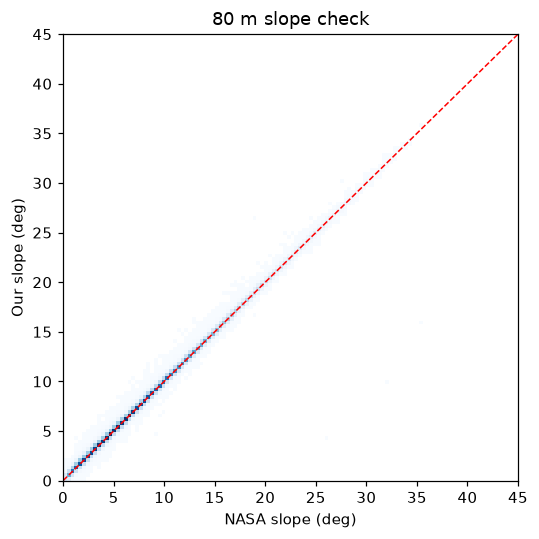

In [21]:
my_slope80 = slope_deg(elev80, RES80)
ok = np.isfinite(my_slope80) & np.isfinite(slope80)
diff = my_slope80[ok] - slope80[ok]
B = dict(median_abs_diff_deg=float(np.median(np.abs(diff))),
         p95_abs_diff_deg=float(np.percentile(np.abs(diff), 95)),
         mean_bias_deg=float(diff.mean()))
print("Our slope minus NASA slope (measured):", {k: round(v, 2) for k, v in B.items()})
print("Looks consistent." if B["median_abs_diff_deg"] < 1 else
      "Bigger than expected. Check units, pixel size, or how NASA defines slope before going on.")

rng = np.random.default_rng(0)
idx = rng.choice(ok.sum(), size=min(200_000, ok.sum()), replace=False)
fig, ax = plt.subplots(figsize=(5, 5))
ax.hist2d(slope80[ok][idx], my_slope80[ok][idx], bins=120, range=[[0, 45], [0, 45]], cmap="Blues", cmin=1)
ax.plot([0, 45], [0, 45], "r--", lw=1)
ax.set_xlabel("NASA slope (deg)"); ax.set_ylabel("Our slope (deg)"); ax.set_title("80 m slope check")
plt.tight_layout(); plt.savefig(FIG / "B_slope_check.png", dpi=150); plt.show()
del my_slope80, diff, ok

## C · First hazard map (80 m, slope only)

Each pixel is classed from slope: **safe** below 15° (VIPER's rating, sourced), **caution** 15–25°, **no-go** at 25° or more (placeholder). Roughness is left out for now.

**Caveat:** an 80 m pixel averages out anything smaller than 80 m, so this map *underestimates* steep ground. Section H measures by how much.

80 m class shares (measured, slope only): {'safe': '82.5%', 'caution': '15.4%', 'no-go': '2.0%'}


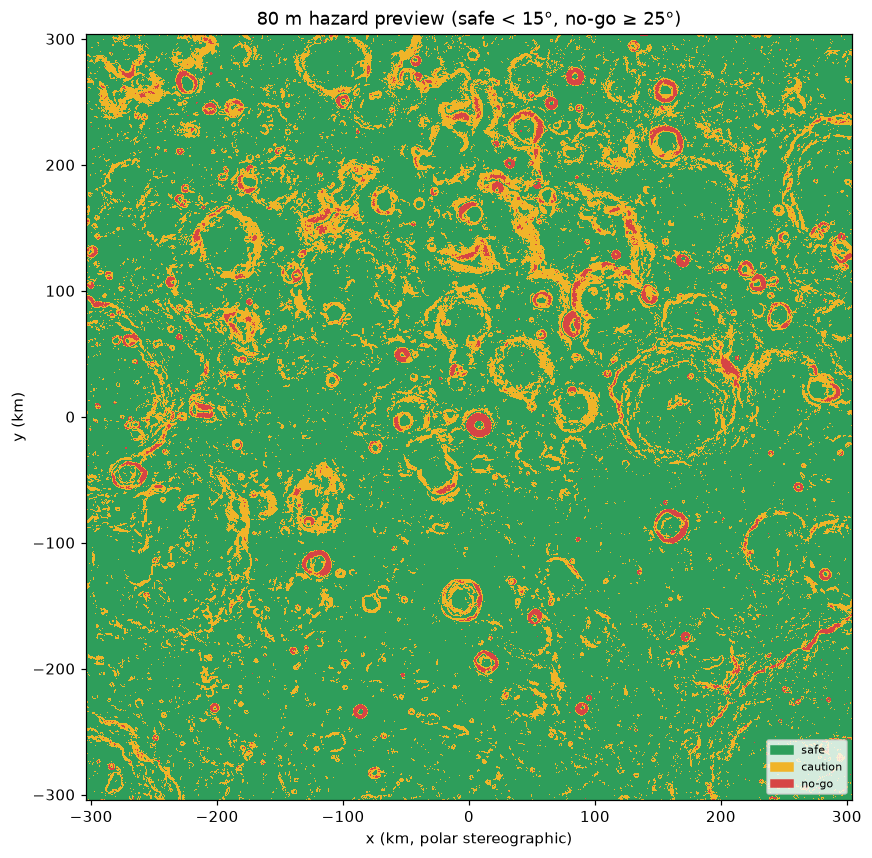

In [22]:
cls80 = classify(slope80)
C = class_fractions(cls80)
print("80 m class shares (measured, slope only):", {k: f"{v:.1%}" for k, v in C.items()})

fig, ax = plt.subplots(figsize=(8, 8))
show_classes(ax, cls80[::2, ::2], ext80, f"80 m hazard preview (safe < {SAFE_MAX_DEG:g}°, no-go ≥ {NOGO_MIN_DEG:g}°)")
km_label(ax); plt.tight_layout(); plt.savefig(FIG / "C_hazard_preview_80m.png", dpi=150); plt.show()
del cls80

## D · Roughness (1 km pixels)

Roughness is how bumpy the ground is around a flat-plane fit, in meters, over a 100 m window. These pixels are 1 km, far too coarse for route planning, but they show which regions are generally rough. The 50 m roughness files (about 600 MB each) can be added later if the team wants roughness in the hazard rule.

Roughness (100 m baseline): median 0.55 m, 2–98% range 0.39–0.82 m


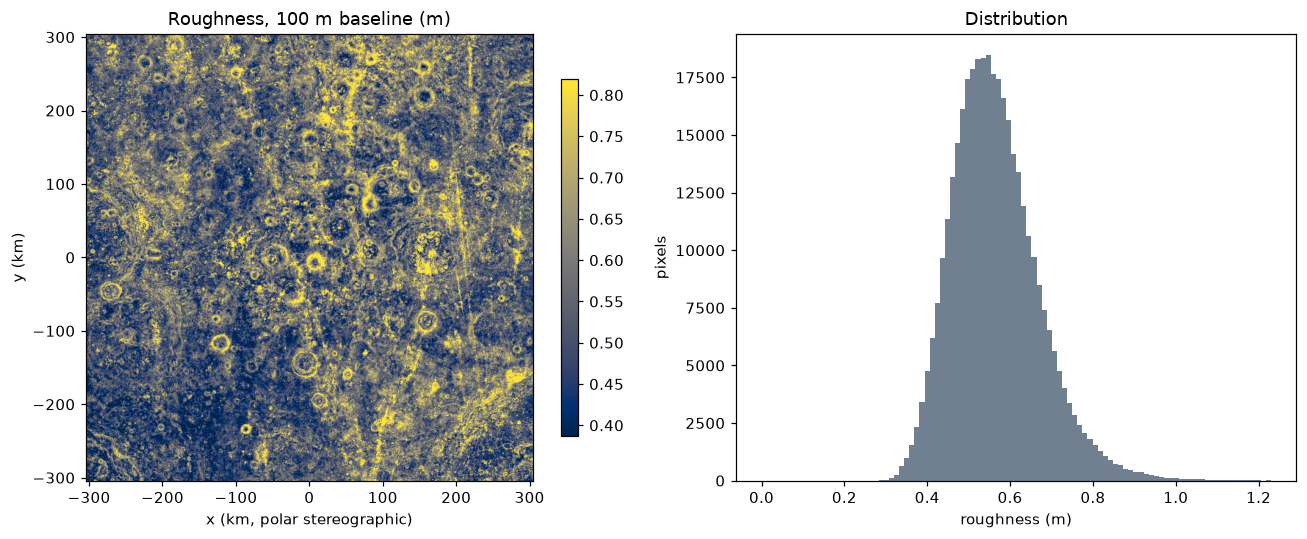

In [23]:
rough, trough = read(F80["rough"])
lo, hi = np.nanpercentile(rough, [2, 98])
print(f"Roughness (100 m baseline): median {np.nanmedian(rough):.2f} m, 2–98% range {lo:.2f}–{hi:.2f} m")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
im = ax[0].imshow(rough, cmap="cividis", vmin=lo, vmax=hi, extent=extent_km(trough, rough.shape))
ax[0].set_title("Roughness, 100 m baseline (m)"); km_label(ax[0]); plt.colorbar(im, ax=ax[0], shrink=0.8)
ax[1].hist(rough[np.isfinite(rough)], bins=100, range=(0, hi * 1.5), color="slategray")
ax[1].set_xlabel("roughness (m)"); ax[1].set_ylabel("pixels"); ax[1].set_title("Distribution")
plt.tight_layout(); plt.savefig(FIG / "D_roughness_1km.png", dpi=150); plt.show()

## E · Permanently shadowed regions (PSRs)

The PSR file lists every shadowed region larger than 1 km² (1,531 of them, sourced from PGDA). We check which one covers Shackleton's floor, because that is Lantern's Profile 1 target, and list the biggest ones.

In [24]:
psr = gpd.read_file(PSR_SHP)
print("PSR polygons:", len(psr), "| columns:", list(psr.columns))
print("PSR CRS:", psr.crs.name if psr.crs else None)

# The PSR file and the rasters use the same polar stereographic meters (PGDA). Check the coordinates line up.
with rasterio.open(F80["elev"]) as s:
    rb = s.bounds
pb = psr.total_bounds
inside = pb[0] >= rb.left - 1 and pb[1] >= rb.bottom - 1 and pb[2] <= rb.right + 1 and pb[3] <= rb.top + 1
print("PSR outlines fall inside the raster grid:", inside)

psr["area_km2"] = psr.geometry.area / 1e6
cent = psr.geometry.centroid
psr["lat"], psr["lon"] = xy_to_latlon(cent.x.values, cent.y.values)
E = dict(n_psr=int(len(psr)), total_area_km2=float(psr.area_km2.sum()))
print(f"Total PSR area > 1 km² (measured): {E['total_area_km2']:,.0f} km²")

hit = psr[psr.contains(Point(*SHACK_XY))]
if len(hit):
    E["shackleton_psr_area_km2"] = float(hit.area_km2.iloc[0])
    print(f"Shackleton's center sits in a PSR of {E['shackleton_psr_area_km2']:.1f} km² (measured)")
else:
    print("No PSR contains the listed Shackleton center. Check the coordinates.")

display(psr.sort_values("area_km2", ascending=False)
           [["area_km2", "lat", "lon"]].head(10).round(2).reset_index(drop=True))

PSR polygons: 1531 | columns: ['gid', 'area_km2', 'name', 'geometry']
PSR CRS: Moon2000_spole
PSR outlines fall inside the raster grid: True
Total PSR area > 1 km² (measured): 18,974 km²
Shackleton's center sits in a PSR of 233.4 km² (measured)


,area_km2,lat,lon
0,1071.43,-88.03,45.30
1,1010.04,-87.49,357.87
2,660.24,-87.15,84.09
3,543.60,-88.25,216.44
4,449.13,-83.52,91.01
5,369.37,-85.02,182.61
6,368.63,-81.69,305.38
7,324.80,-83.89,118.47
8,304.49,-82.17,11.12
9,303.31,-84.46,313.68


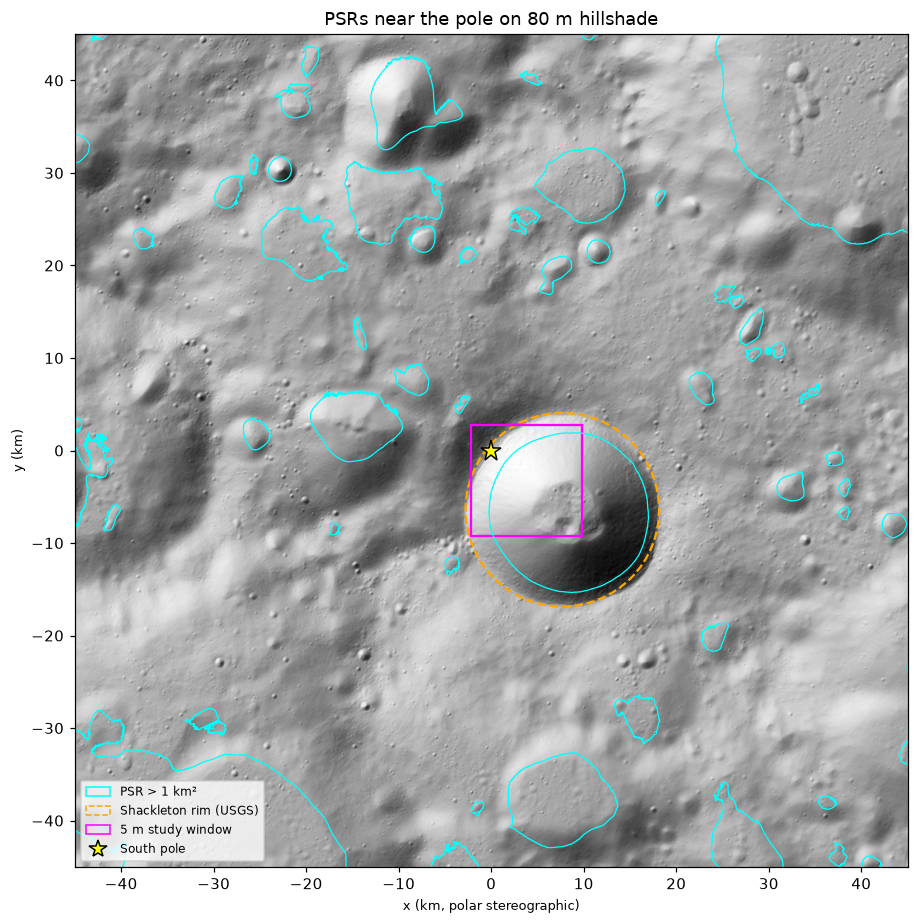

In [25]:
Z = 45_000  # half-width of the zoom box around the pole (m)
hs_z, ext_z = subset(elev80, t80, -Z, Z, -Z, Z)
hs_z = hillshade(hs_z, RES80)
fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.imshow(hs_z, cmap="gray", extent=ext_z)
psr.cx[-Z:Z, -Z:Z].geometry.scale(1e-3, 1e-3, origin=(0, 0)).boundary.plot(ax=ax, color="cyan", lw=0.8)
ax.add_patch(Circle((SHACK_XY[0] / 1e3, SHACK_XY[1] / 1e3), SHACKLETON_DIAM_KM / 2, fill=False, ec="orange", lw=1.5, ls="--"))
l, b, r, t = [v / 1e3 for v in CROP_BOUNDS]
ax.add_patch(Rectangle((l, b), r - l, t - b, fill=False, ec="magenta", lw=1.5))
ax.plot(0, 0, marker="*", color="yellow", ms=14, mec="k")
ax.set_xlim(-Z / 1e3, Z / 1e3); ax.set_ylim(-Z / 1e3, Z / 1e3)
ax.legend(handles=[Patch(ec="cyan", fc="none", label="PSR > 1 km²"),
                   Patch(ec="orange", fc="none", ls="--", label="Shackleton rim (USGS)"),
                   Patch(ec="magenta", fc="none", label="5 m study window"),
                   plt.Line2D([], [], marker="*", color="yellow", mec="k", ls="", ms=12, label="South pole")],
          loc="lower left", fontsize=8)
ax.set_title("PSRs near the pole on 80 m hillshade"); km_label(ax)
plt.tight_layout(); plt.savefig(FIG / "E_psr_pole_zoom.png", dpi=150); plt.show()

## F · 5 m study window: Shackleton rim to floor

This reads only a 12 × 12 km piece of the 5 m elevation and slope maps (3.3 GB and 4.9 GB files) straight from NASA's server, then saves it to `~/lunar/data/crops/` so later notebooks don't fetch it again. The 5 m count map comes from your download.

If the HTTP read fails or crawls, download the full files instead (separate terminal tab), then re-run this cell:
```
aria2c -c -x 4 -s 4 -d ~/lunar/data https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/87S/ldem_87s_5mpp.tif
aria2c -c -x 4 -s 4 -d ~/lunar/data https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/87S/ldsm_87s_5mpp.tif
```

In [26]:
def read_crop(name, bounds):
    cache = CROPS / name.replace(".tif", "_crop.tif")
    if cache.exists():
        return read(cache)
    path, remote = source_5m(name)
    print(f"Reading {name} {'over HTTP' if remote else 'from disk'} ...", end=" ", flush=True)
    t0 = time.time()
    try:
        with rasterio.Env(**GDAL_HTTP_ENV), rasterio.open(path) as s:
            if remote and not s.profile.get("tiled"):
                print("\n  (file is not tiled, so a window read may pull extra data and be slow)", end=" ")
            w = from_bounds(*bounds, transform=s.transform)
            w = Window(round(w.col_off), round(w.row_off), round(w.width), round(w.height))
            w = w.intersection(Window(0, 0, s.width, s.height))
            a = np.ma.filled(s.read(1, window=w, masked=True).astype("float32"), np.nan)
            t, crs = s.window_transform(w), s.crs
    except Exception as e:
        print(f"\nCould not read {path}: {e}\nDownload the full file with the aria2c command above, then re-run.")
        raise
    a[np.abs(a) > 1e30] = np.nan
    prof = dict(driver="GTiff", width=a.shape[1], height=a.shape[0], count=1, dtype="float32", crs=crs,
                transform=t, nodata=np.nan, compress="deflate", tiled=True, blockxsize=256, blockysize=256)
    with rasterio.open(cache, "w", **prof) as d:
        d.write(a, 1)
    print(f"done in {time.time() - t0:.0f} s, {a.nbytes / 1e6:.0f} MB, cached to {cache.name}")
    return a, t

elev5, t5 = read_crop(F5["elev"], CROP_BOUNDS)
slope5, ts5 = read_crop(F5["slope"], CROP_BOUNDS)
count5, tc5 = read_crop(F5["count"], CROP_BOUNDS)
assert elev5.shape == slope5.shape == count5.shape and t5 == ts5 == tc5, "5 m crops are not on the same grid"
RES5 = t5.a
ext5 = extent_km(t5, elev5.shape)
print(f"5 m window: {elev5.shape} pixels at {RES5:.0f} m, elevation {np.nanmin(elev5):,.0f} to {np.nanmax(elev5):,.0f} m")

my5 = slope_deg(elev5, RES5)
ok = np.isfinite(my5) & np.isfinite(slope5)
print(f"Our 5 m slope vs NASA 5 m slope (measured): median |diff| {np.median(np.abs(my5[ok] - slope5[ok])):.2f} deg")
del my5, ok

Reading ldem_87s_5mpp.tif from disk ... done in 0 s, 23 MB, cached to ldem_87s_5mpp_crop.tif
Reading ldsm_87s_5mpp.tif over HTTP ... done in 79 s, 23 MB, cached to ldsm_87s_5mpp_crop.tif
Reading ldec_87s_5mpp.tif from disk ... done in 0 s, 23 MB, cached to ldec_87s_5mpp_crop.tif
5 m window: (2400, 2400) pixels at 5 m, elevation -2,854 to 1,598 m
Our 5 m slope vs NASA 5 m slope (measured): median |diff| 0.00 deg


5 m class shares in the window (measured, slope only): {'safe': '21.5%', 'caution': '14.2%', 'no-go': '64.4%'}


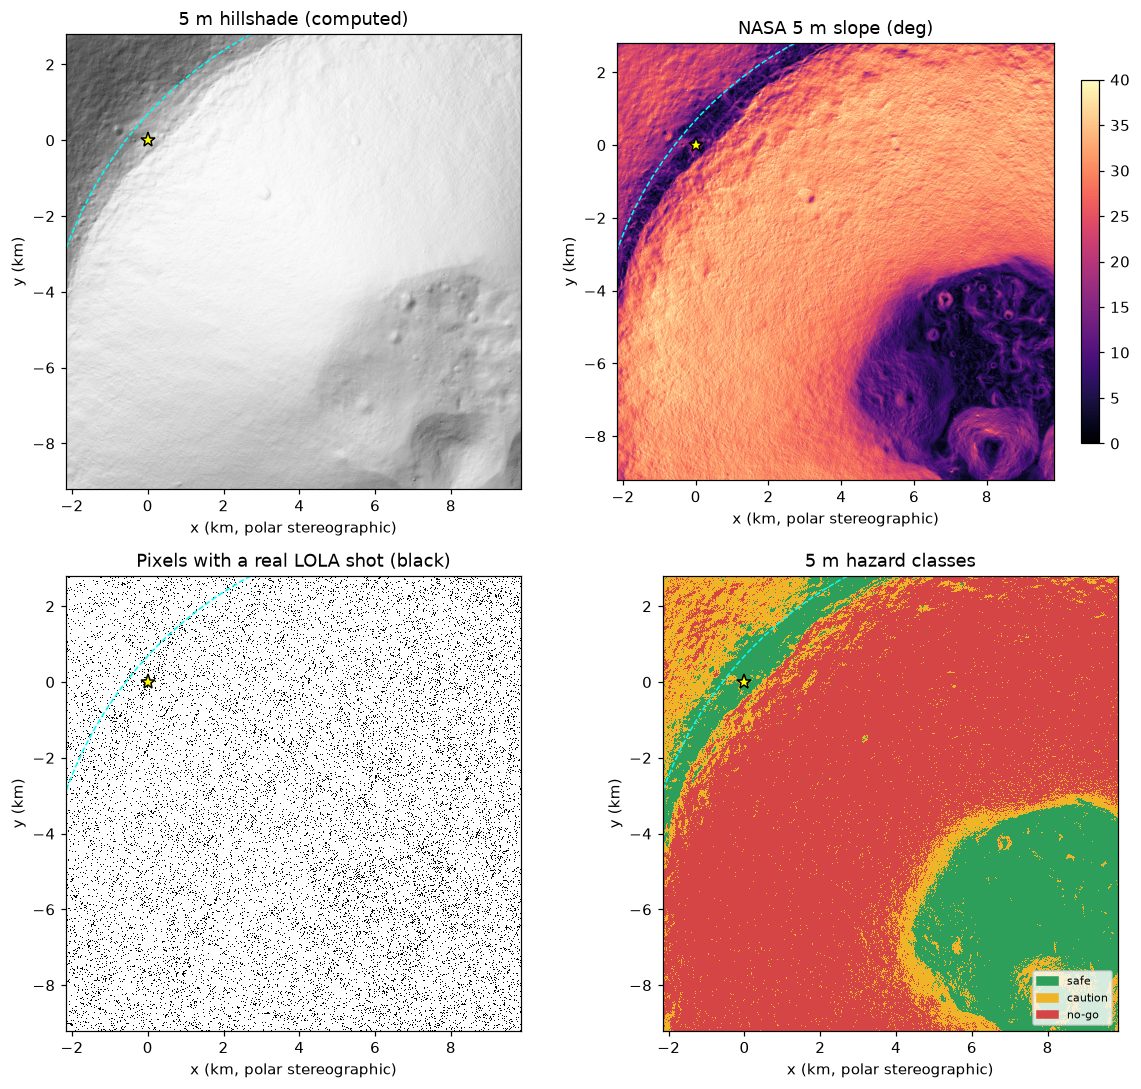

In [27]:
cls5 = classify(slope5)
F = class_fractions(cls5)
print("5 m class shares in the window (measured, slope only):", {k: f"{v:.1%}" for k, v in F.items()})

fig, ax = plt.subplots(2, 2, figsize=(11, 10))
ax[0, 0].imshow(hillshade(elev5, RES5), cmap="gray", extent=ext5); ax[0, 0].set_title("5 m hillshade (computed)")
im = ax[0, 1].imshow(slope5, cmap="magma", vmin=0, vmax=40, extent=ext5); ax[0, 1].set_title("NASA 5 m slope (deg)")
plt.colorbar(im, ax=ax[0, 1], shrink=0.8)
ax[1, 0].imshow(np.isfinite(count5) & (count5 > 0), cmap="Greys", extent=ext5, interpolation="nearest")
ax[1, 0].set_title("Pixels with a real LOLA shot (black)")
show_classes(ax[1, 1], cls5, ext5, "5 m hazard classes")
for a in ax.flat:
    a.add_patch(Circle((SHACK_XY[0] / 1e3, SHACK_XY[1] / 1e3), SHACKLETON_DIAM_KM / 2, fill=False, ec="cyan", lw=1, ls="--"))
    a.plot(0, 0, marker="*", color="yellow", ms=10, mec="k")
    a.set_xlim(ext5[0], ext5[1]); a.set_ylim(ext5[2], ext5[3]); km_label(a)
plt.tight_layout(); plt.savefig(FIG / "F_shackleton_5m.png", dpi=150); plt.show()

## G · How much of the 5 m map is real?

The 5 m map is built from LOLA laser tracks, and the gaps between tracks are filled in. The count map says how many shots landed in each pixel; zero means the height there was interpolated. The project plan assumed about 90% interpolation, and this checks that figure. Counts can be fractions where neighboring map tiles were blended (sourced from the PGDA page), so both "> 0" and "≥ 1" are reported.

In [28]:
v = np.isfinite(count5)
G = dict(window_frac_real_gt0=float((count5[v] > 0).mean()), window_frac_real_ge1=float((count5[v] >= 1).mean()))
print(f"Study window: {G['window_frac_real_gt0']:.1%} of pixels have a shot (> 0), "
      f"{G['window_frac_real_ge1']:.1%} have ≥ 1 (measured)")

path, remote = source_5m(F5["count"])
if RUN_FULL_COUNT and not remote:
    R87 = 2 * MOON_R * np.tan(np.radians(3) / 2)          # radius of the 87°S circle in the grid (m)
    n_valid = n_gt0 = n_ge1 = 0
    with rasterio.open(path) as s:
        t, W, H = s.transform, s.width, s.height
        xs2 = ((t.c + t.a * (np.arange(W) + 0.5)) ** 2).astype("float64")
        step = 256
        t0 = time.time()
        for r in range(0, H, step):
            h = min(step, H - r)
            a = s.read(1, window=Window(0, r, W, h), masked=True)
            a = np.ma.filled(a.astype("float32"), np.nan)
            ys2 = (t.f + t.e * (np.arange(r, r + h) + 0.5)) ** 2
            m = np.isfinite(a) & ((xs2[None, :] + ys2[:, None]) <= R87 ** 2)
            vals = a[m]
            n_valid += vals.size; n_gt0 += int((vals > 0).sum()); n_ge1 += int((vals >= 1).sum())
            if (r // step) % 20 == 0:
                print(f"\r  scanned {r + h:,}/{H:,} rows", end="", flush=True)
    G.update(full_frac_real_gt0=n_gt0 / n_valid, full_frac_real_ge1=n_ge1 / n_valid, full_pixels=n_valid)
    print(f"\nWhole 87–90°S mosaic: {G['full_frac_real_gt0']:.1%} of {n_valid:,} pixels have a shot (> 0), "
          f"{G['full_frac_real_ge1']:.1%} have ≥ 1 (measured, {time.time() - t0:.0f} s)")
    print(f"So about {1 - G['full_frac_real_gt0']:.0%} of 5 m pixels are interpolated.")
else:
    print("Skipped the full-mosaic scan (count map not on disk, or RUN_FULL_COUNT is False).")

Study window: 8.8% of pixels have a shot (> 0), 8.8% have ≥ 1 (measured)
  scanned 36,096/40,000 rows
Whole 87–90°S mosaic: 7.1% of 1,040,411,592 pixels have a shot (> 0), 7.1% have ≥ 1 (measured, 7 s)
So about 93% of 5 m pixels are interpolated.


## H · Baseline: how much does a coarse map miss?

This is the number the whole ML plan hangs on. We treat the 5 m hazard classes as the truth and ask two cheap methods to find the no-go ground:

* **20 m rule:** average the 5 m elevation to 20 m pixels, compute slope, apply the same thresholds.
* **80 m rule:** apply the thresholds to NASA's 80 m slope map.

**No-go recall** is the share of real 5 m no-go pixels that a method also flags. Missing a cliff is worse than a false alarm, so recall matters most. If the 20 m rule already catches nearly all no-go ground, the U-Net has little to add. If it misses a lot, that gap is what the U-Net is for.

Scores are given twice: on all pixels, and only on pixels with a real LOLA shot, so we can tell whether the result depends on interpolated terrain. A 16-pixel (80 m) border is left out to avoid edge effects.

,method,scored_on,nogo_recall,nogo_precision,nogo_f1,class_agreement,pixels,truth_nogo_pixels
0,20 m slope rule,all pixels,0.981,0.964,0.973,0.950,5607424,3636242
1,20 m slope rule,LOLA-shot pixels only,0.980,0.953,0.967,0.942,496103,307039
2,80 m slope rule,all pixels,0.968,0.953,0.961,0.924,5607424,3636242
3,80 m slope rule,LOLA-shot pixels only,0.971,0.943,0.956,0.919,496103,307039


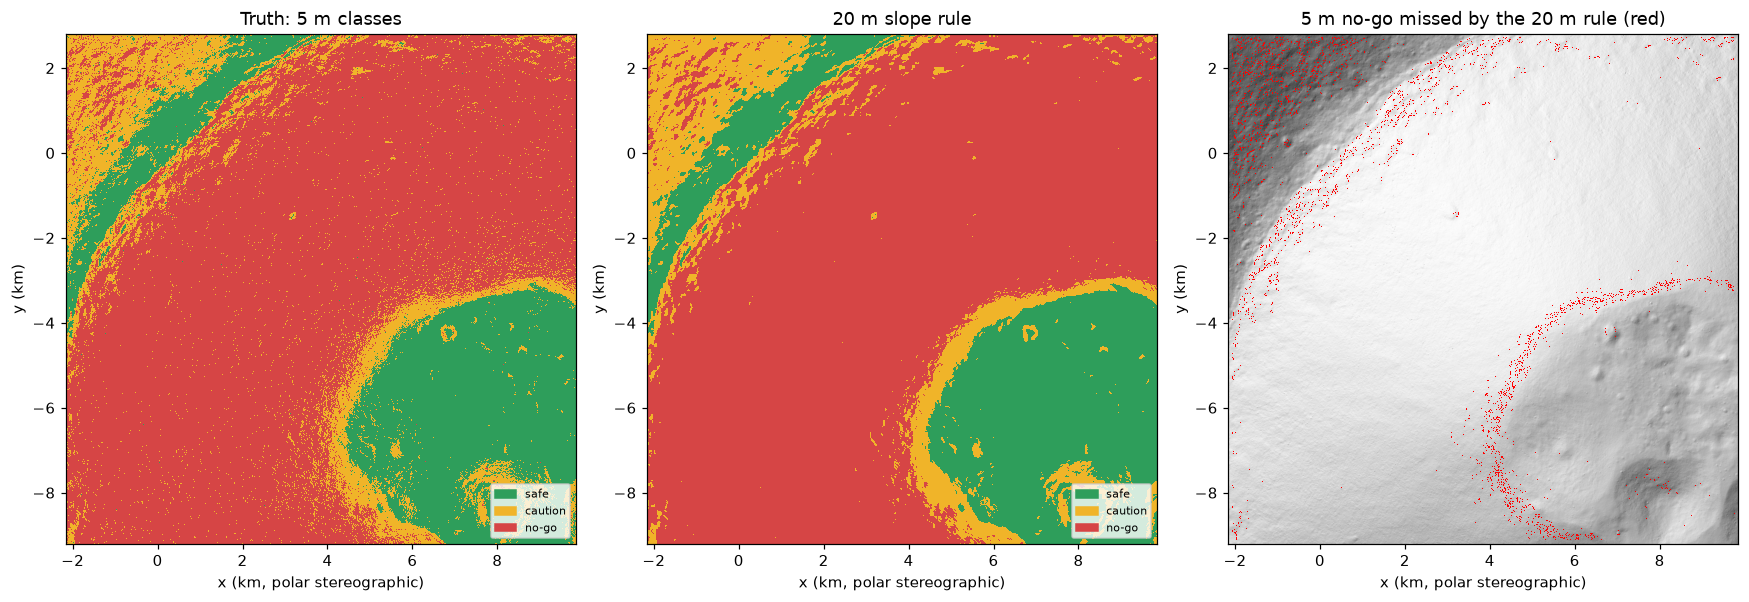

In [29]:
f = 4
H, W = (elev5.shape[0] // f) * f, (elev5.shape[1] // f) * f
truth = cls5[:H, :W]

elev20 = elev5[:H, :W].reshape(H // f, f, W // f, f).mean(axis=(1, 3))      # 20 m DEM (block mean)
cls20 = np.repeat(np.repeat(classify(slope_deg(elev20, RES5 * f)), f, 0), f, 1)

xs = t5.c + t5.a * (np.arange(W) + 0.5)
ys = t5.f + t5.e * (np.arange(H) + 0.5)
c80 = np.floor((xs - t80.c) / t80.a).astype(int)
r80 = np.floor((ys - t80.f) / t80.e).astype(int)
cls80w = classify(slope80[r80[:, None], c80[None, :]])                     # 80 m map sampled at 5 m centers

BORDER = 16
mask = np.zeros((H, W), bool); mask[BORDER:-BORDER, BORDER:-BORDER] = True
mask &= (truth != NODATA_CLASS) & (cls20 != NODATA_CLASS) & (cls80w != NODATA_CLASS)
real = mask & (count5[:H, :W] > 0)
extH = extent_km(t5, (H, W))

def scores(pred, m):
    t, p = (truth == 2) & m, (pred == 2) & m
    tp, fn, fp = (t & p).sum(), (t & ~p).sum(), (~t & p).sum()
    rec = tp / (tp + fn) if tp + fn else np.nan
    prec = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else np.nan
    return dict(nogo_recall=rec, nogo_precision=prec, nogo_f1=f1,
                class_agreement=float((truth[m] == pred[m]).mean()),
                pixels=int(m.sum()), truth_nogo_pixels=int(t.sum()))

rows = []
for name, pred in [("20 m slope rule", cls20), ("80 m slope rule", cls80w)]:
    for subset_name, m in [("all pixels", mask), ("LOLA-shot pixels only", real)]:
        rows.append(dict(method=name, scored_on=subset_name, **scores(pred, m)))
Htab = pd.DataFrame(rows)
display(Htab.round(3))

miss = (truth == 2) & (cls20 != 2) & mask
fig, ax = plt.subplots(1, 3, figsize=(16, 5.6))
show_classes(ax[0], truth, extH, "Truth: 5 m classes")
show_classes(ax[1], cls20, extH, "20 m slope rule")
ax[2].imshow(hillshade(elev5[:H, :W], RES5), cmap="gray", extent=extH)
ax[2].imshow(np.ma.masked_where(~miss, miss), cmap=ListedColormap(["red"]), extent=extH, interpolation="nearest")
ax[2].set_title("5 m no-go missed by the 20 m rule (red)")
for a in ax: km_label(a)
plt.tight_layout(); plt.savefig(FIG / "H_baseline_misses.png", dpi=150); plt.show()

## Summary

Everything measured above goes into `results/m1_summary.json`, so the numbers can be quoted in the README and proposal with their labels. All figures are in `figures/`.

In [30]:
def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    return o

summary = clean({
    "settings": {
        "safe_max_deg": {"value": SAFE_MAX_DEG, "label": "sourced: NASA VIPER rover page (15 deg incline)"},
        "nogo_min_deg": {"value": NOGO_MIN_DEG, "label": "placeholder: project plan, rover not chosen"},
        "crop_km": CROP_KM, "crop_bounds_m": CROP_BOUNDS,
    },
    "measured": {
        "B_slope_check_80m": B,
        "C_class_shares_80m": C,
        "E_psr": E,
        "F_class_shares_5m_window": F,
        "G_real_vs_interpolated": G,
        "H_baseline": Htab.to_dict(orient="records"),
    },
    "data_citations": ["Barker et al. 2023, PSJ 4, 183, doi:10.3847/PSJ/acf3e1",
                       "Barker et al. 2021, PSS 203, 105119, doi:10.1016/j.pss.2020.105119"],
})
(RESULTS / "m1_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary["measured"], indent=2))

{
  "B_slope_check_80m": {
    "median_abs_diff_deg": 0.1256,
    "p95_abs_diff_deg": 0.5539,
    "mean_bias_deg": 0.012
  },
  "C_class_shares_80m": {
    "safe": 0.8254,
    "caution": 0.1542,
    "no-go": 0.0205
  },
  "E_psr": {
    "n_psr": 1531,
    "total_area_km2": 18973.9485,
    "shackleton_psr_area_km2": 233.4218
  },
  "F_class_shares_5m_window": {
    "safe": 0.2146,
    "caution": 0.1417,
    "no-go": 0.6436
  },
  "G_real_vs_interpolated": {
    "window_frac_real_gt0": 0.0885,
    "window_frac_real_ge1": 0.0885,
    "full_frac_real_gt0": 0.0713,
    "full_frac_real_ge1": 0.0713,
    "full_pixels": 1040411592
  },
  "H_baseline": [
    {
      "method": "20 m slope rule",
      "scored_on": "all pixels",
      "nogo_recall": 0.9811,
      "nogo_precision": 0.9642,
      "nogo_f1": 0.9726,
      "class_agreement": 0.95,
      "pixels": 5607424,
      "truth_nogo_pixels": 3636242
    },
    {
      "method": "20 m slope rule",
      "scored_on": "LOLA-shot pixels only",
   

## What to look at before Milestone 2

* **Section B:** a median slope difference well under 1° means the slope code is safe to reuse.
* **Section G:** the real interpolated share. If it is far from 90%, update the project plan.
* **Section H:** no-go recall for the 20 m rule. Low recall (many red pixels) is the gap the U-Net has to close. High recall on all pixels but lower recall on LOLA-shot pixels would mean the interpolation is hiding real hazards.
* Bring the PSR table and the Section F figure to the team. They show Lantern's rim-to-floor path at 5 m.

Next notebook: `02_make_labels.ipynb` turns the cached 5 m window(s) into 128 × 128 training patches.